<a href="https://colab.research.google.com/github/Shreya123714/AC-DC-Power-System-Simulation/blob/main/AC_DC_Power_System_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Part 1: Rectifier ---
Peak output: 323.87 V | Average DC: 316.92 V
Ripple (simulation): 14.29 V | Ripple (formula Vp/2fRC): 16.19 V
Ripple factor: 1.3 %
--- Part 2: DC plant ---
Outage: 4.0 h | Min SoC: 70.5% | Site downtime: 0 min
Availability over 8 h: 100.00%
Energy from grid: 13.28 kWh
54.0


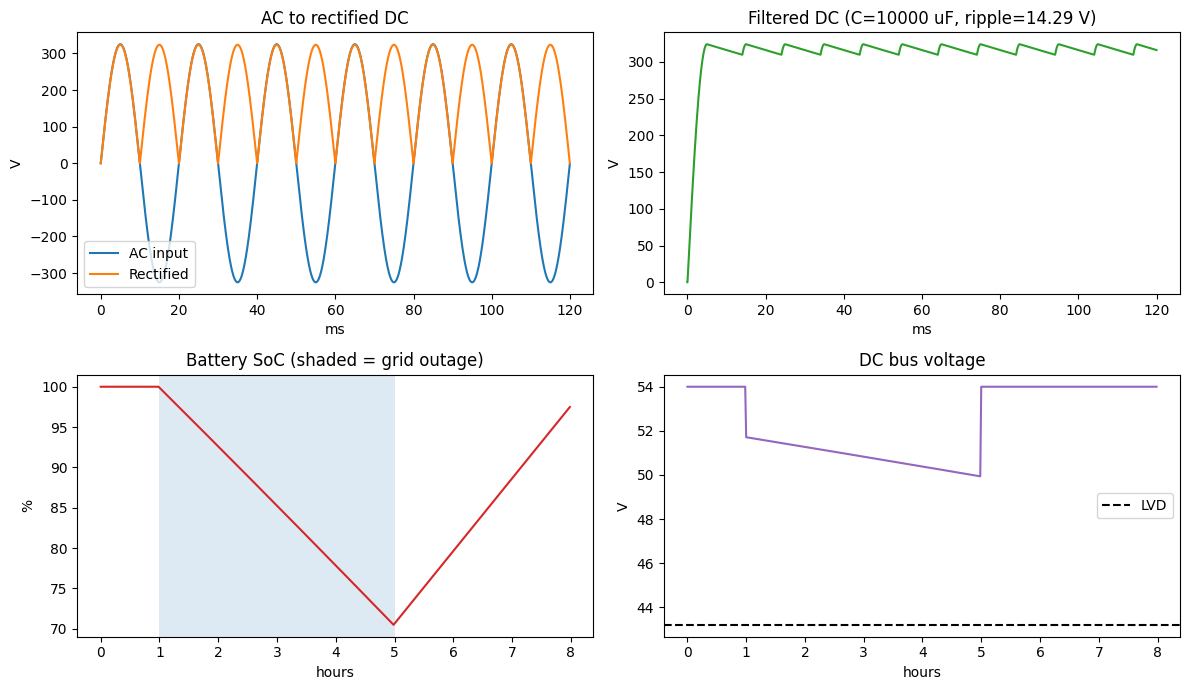

In [10]:
"""
AC-DC Power System Simulation
Part 1: Full-wave bridge rectifier + capacitor filter (AC -> DC, ripple)
Part 2: -48V DC plant: rectifier + battery through a grid outage
"""
import numpy as np
import matplotlib.pyplot as plt

# =========================================================== PART 1: RECTIFIER
f = 50.0            # grid frequency (Hz)
Vrms = 230         # transformer secondary (V rms)  -> try 230 to see why we step down
Vd = 0.7            # diode drop (V); bridge has 2 diodes in the path
R = 20.0            # load resistance (ohm)
C = 10000e-6         # filter capacitor (F)
dt = 1e-5
t = np.arange(0, 0.12, dt)
vin = Vrms * np.sqrt(2) * np.sin(2 * np.pi * f * t)
vrect = np.maximum(np.abs(vin) - 2 * Vd, 0)       # full-wave rectified, no filter

vc = np.zeros_like(t)                             # filtered output
for k in range(1, len(t)):
    v_discharge = vc[k - 1] - (vc[k - 1] / (R * C)) * dt   # capacitor feeds load
    vc[k] = max(vrect[k], v_discharge)                     # diode conducts if input is higher

last = vc[int(0.08 / dt):]                        # steady state (after ~4 cycles)
ripple_sim = last.max() - last.min()
ripple_formula = last.max() / (2 * f * R * C)     # standard approximation
vdc_avg = last.mean()
print("--- Part 1: Rectifier ---")
print(f"Peak output: {last.max():.2f} V | Average DC: {vdc_avg:.2f} V")
print(f"Ripple (simulation): {ripple_sim:.2f} V | Ripple (formula Vp/2fRC): {ripple_formula:.2f} V")
print(f"Ripple factor: {ripple_sim / (2*np.sqrt(3)) / vdc_avg * 100:.1f} %")

# ============================================== PART 2: -48V PLANT + BATTERY
P_load = 1500.0           # DC load (W)
batt_ah = 400.0           # usable battery capacity (Ah)
r_int = 0.01              # battery internal resistance (ohm)
v_float = 54.0            # rectifier float voltage (V)
rect_eff = 0.94
charge_limit = 0.10 * batt_ah    # 0.1C charge current limit (A)
lvd = 43.2                # low voltage disconnect (V)
out_start, out_end = 60, 300     # grid outage window (minutes)
T = 480                   # total sim time (minutes)

soc = 1.0
ts, socs, vbus, ac_kw, up = [], [], [], [], []
downtime = 0
for m in range(T):
    grid = not (out_start <= m < out_end)
    ocv = 46.0 + 6.0 * soc                        # simple OCV vs SoC model (46..52 V)
    if grid:
        v = v_float
        i_load = P_load / v
        i_chg = charge_limit if soc < 0.999 else 0.0
        p_ac = (v * (i_load + i_chg)) / rect_eff
        soc = min(1.0, soc + (i_chg * 0.9) / 60 / batt_ah)    # 90% charge efficiency
        alive = True
    else:
        # solve battery current for constant power: V = OCV - I*r, P = V*I
        i = P_load / ocv
        for _ in range(5):
            i = P_load / (ocv - i * r_int)
        v = ocv - i * r_int
        alive = v > lvd and soc > 0.0
        if alive:
            soc = max(0.0, soc - i / 60 / batt_ah)
        else:
            downtime += 1
        p_ac = 0.0
    ts.append(m / 60); socs.append(soc * 100); vbus.append(v if alive else 0)
    ac_kw.append(p_ac / 1000); up.append(alive)

print("--- Part 2: DC plant ---")
print(f"Outage: {(out_end-out_start)/60:.1f} h | Min SoC: {min(socs):.1f}% | Site downtime: {downtime} min")
print(f"Availability over {T/60:.0f} h: {100*(1-downtime/T):.2f}%")
print(f"Energy from grid: {sum(ac_kw)/60:.2f} kWh")
print(v_float)
# ================================================================= PLOTS
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].plot(t * 1000, vin, label="AC input"); ax[0, 0].plot(t * 1000, vrect, label="Rectified")
ax[0, 0].set(title="AC to rectified DC", xlabel="ms", ylabel="V"); ax[0, 0].legend()
ax[0, 1].plot(t * 1000, vc, color="tab:green"); ax[0, 1].set(title=f"Filtered DC (C={C*1e6:.0f} uF, ripple={ripple_sim:.2f} V)", xlabel="ms", ylabel="V")
ax[1, 0].plot(ts, socs, color="tab:red"); ax[1, 0].axvspan(out_start/60, out_end/60, alpha=0.15)
ax[1, 0].set(title="Battery SoC (shaded = grid outage)", xlabel="hours", ylabel="%")
ax[1, 1].plot(ts, vbus, color="tab:purple"); ax[1, 1].axhline(lvd, ls="--", c="k", label="LVD")
ax[1, 1].set(title="DC bus voltage", xlabel="hours", ylabel="V"); ax[1, 1].legend()
plt.tight_layout(); plt.show()
